# Phase 1 — Data Alignment & Exploratory Analysis

**Goal:** Produce `merged_dataset.parquet` — a single source of truth where every row has:
`[song_id, allmusic_id, quadrant, arousal, valence, artist, title, duration, year, audio_path, lyrics_path, lyrics_text, has_audio, has_lyrics, is_multimodal]`

### ID Scheme
The dataset has three kinds of songs:

| Type | Count | Audio filename | Lyrics filename |
|------|-------|---------------|-----------------|
| MT-type | 3,099 | `{Song}.mp3` | `{Song}.txt` (Song = AllMusic Id) |
| A-compound | 69 | `{Song}.mp3` e.g. `A064-116` | secondary-number bridge → `Lxxx-116.txt` |
| A-simple | 64 | `{Song}.mp3` e.g. `A005` | no lyrics available |

In [1]:
import os
import glob
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

BASE = os.path.dirname(os.path.abspath('.'))
ROOT = os.path.join(os.path.dirname(os.path.abspath('.')), 'music_research')
ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
AUDIO_ROOT  = os.path.join(ROOT, 'MERGE_Audio_Balanced')
LYRICS_ROOT = os.path.join(ROOT, 'MERGE_Lyrics_Balanced')
OUT_DIR     = os.path.join(ROOT, 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)

QUADRANT_LABELS = {
    'Q1': 'Happy (High A, High V)',
    'Q2': 'Angry (High A, Low V)',
    'Q3': 'Sad (Low A, Low V)',
    'Q4': 'Calm (Low A, High V)',
}
QUADRANT_COLORS = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}

print('Paths configured.')
print('  Audio root:', AUDIO_ROOT)
print('  Lyrics root:', LYRICS_ROOT)
print('  Output dir:', OUT_DIR)

Paths configured.
  Audio root: <ROOT>\MERGE_Audio_Balanced
  Lyrics root: <ROOT>\MERGE_Lyrics_Balanced
  Output dir: <ROOT>\outputs


## 1. Load CSVs

In [2]:
meta = pd.read_csv(os.path.join(AUDIO_ROOT, 'merge_audio_balanced_metadata.csv'))
av   = pd.read_csv(os.path.join(AUDIO_ROOT, 'merge_audio_balanced_av_values.csv'))

print(f'Metadata: {meta.shape[0]} rows, {meta.shape[1]} columns')
print(f'AV values: {av.shape[0]} rows')
print()
print('Metadata columns:')
print(meta.columns.tolist())
meta.head(3)

Metadata: 3232 rows, 26 columns
AV values: 3232 rows

Metadata columns:
['Song', 'Quadrant', 'AllMusic Id', 'AllMusic Extraction Date', 'Artist', 'Title', 'Relevance', 'Year', 'LowestYear', 'Duration', 'Moods', 'MoodsAll', 'MoodsAllWeights', 'Genres', 'GenreWeights', 'Themes', 'ThemeWeights', 'Styles', 'StyleWeights', 'AppearancesTrackIDs', 'AppearancesAlbumIDs', 'Sample', 'SampleURL', 'ActualYear', 'num_Genres', 'num_MoodsAll']


,Song,Quadrant,AllMusic Id,AllMusic Extraction Date,Artist,Title,Relevance,Year,LowestYear,Duration,...,ThemeWeights,Styles,StyleWeights,AppearancesTrackIDs,AppearancesAlbumIDs,Sample,SampleURL,ActualYear,num_Genres,num_MoodsAll
0,A001,Q4,MT0000291374,New,Louis Armstrong,What a Wonderful World,NaN,NaN,NaN,139.0,...,"9,9",NaN,NaN,NaN,NaN,NaN,NaN,1968,NaN,NaN
1,A002,Q4,MT0001577585,Old,Rod Stewart,Country Comfort,1.493585,1970-??-??,NaN,282.0,...,"5,5,5,5,5,5,5,5","Adult Contemporary,Contemporary Pop/Rock","5,5","MT0001577585,MT0002372349,MT0002706336,MT00029...","MW0000073575,MW0000100670,MW0000100670,MW00001...",1.0,http://rovimusic.rovicorp.com/playback.mp3?c=s...,1970,NaN,NaN
2,A003,Q3,MT0008469560,New,Stevie Wonder,Lately,NaN,NaN,NaN,244.0,...,"7,8,9,9,9",NaN,NaN,NaN,NaN,NaN,NaN,1980,NaN,NaN


In [3]:
# Merge AV scores into metadata — both share the Song key
df = meta.merge(av, on='Song', how='left')
assert len(df) == len(meta), 'Row count changed after merge'
print(f'Null Arousal: {df["Arousal"].isna().sum()}, Null Valence: {df["Valence"].isna().sum()}')
df[['Song', 'AllMusic Id', 'Quadrant', 'Arousal', 'Valence', 'Artist', 'Title']].head(5)

Null Arousal: 0, Null Valence: 0


,Song,AllMusic Id,Quadrant,Arousal,Valence,Artist,Title
0,A001,MT0000291374,Q4,0.2250,0.8750,Louis Armstrong,What a Wonderful World
1,A002,MT0001577585,Q4,0.3750,0.7125,Rod Stewart,Country Comfort
2,A003,MT0008469560,Q3,0.2125,0.2500,Stevie Wonder,Lately
3,A004,MT0030326044,Q3,0.1625,0.2250,Johnny Cash,I'm So Lonesome I Could Cry
4,A005,MT0005204984,Q1,0.7875,0.7125,Prince,U Got the Look


## 2. Build File Index Maps

In [4]:
def build_file_map(root, extension, quadrants=('Q1','Q2','Q3','Q4')):
    """Returns {stem: absolute_path} for all files with the given extension under root/Qx/."""
    file_map = {}
    for q in quadrants:
        pattern = os.path.join(root, q, f'*.{extension}')
        for path in glob.glob(pattern):
            stem = os.path.splitext(os.path.basename(path))[0]
            file_map[stem] = path
    return file_map

audio_map  = build_file_map(AUDIO_ROOT,  'mp3')
lyrics_map = build_file_map(LYRICS_ROOT, 'txt')

print(f'Audio files indexed: {len(audio_map)}')
print(f'Lyrics files indexed: {len(lyrics_map)}')

# Categorise by ID type
def id_type(stem):
    if stem.startswith('MT'):
        return 'MT'
    if re.match(r'^A\d+$', stem):
        return 'A_simple'
    if re.match(r'^A\d+-\d+$', stem):
        return 'A_compound'
    if re.match(r'^L\d+$', stem):
        return 'L_simple'
    if re.match(r'^L\d+-\d+$', stem):
        return 'L_compound'
    return 'other'

audio_types  = pd.Series({s: id_type(s) for s in audio_map}).value_counts()
lyrics_types = pd.Series({s: id_type(s) for s in lyrics_map}).value_counts()
print('\nAudio file types:')
print(audio_types.to_string())
print('\nLyrics file types:')
print(lyrics_types.to_string())

Audio files indexed: 3232
Lyrics files indexed: 2400

Audio file types:
MT            3099
A_compound      69
A_simple        64

Lyrics file types:
MT            2243
L_simple        79
L_compound      78


## 3. Resolve Linkages → Master DataFrame

Three lookup rules applied in priority order:
1. **MT-type**: `Song` (= `AllMusic Id`) is directly the audio stem and the lyrics stem.
2. **A-compound**: audio stem is `Song` (e.g. `A064-116`); lyrics stem is the L-compound file sharing the same **secondary number** (e.g. `L114-116`).
3. **A-simple**: audio stem is `Song`; no lyrics.

In [5]:
# Build reverse index: secondary_number -> L-compound lyric path
secondary_to_lyrics = {}
for stem, path in lyrics_map.items():
    if re.match(r'^L\d+-\d+$', stem):
        secondary = stem.split('-')[1]
        secondary_to_lyrics[secondary] = path

print(f'L-compound lyric files (secondary-number indexed): {len(secondary_to_lyrics)}')

def resolve_audio_path(song_id):
    return audio_map.get(song_id)

def resolve_lyrics_path(song_id):
    # Rule 1: MT-type — song_id is also the lyrics stem
    if song_id.startswith('MT'):
        return lyrics_map.get(song_id)
    # Rule 2: A-compound — bridge via secondary number
    if re.match(r'^A\d+-\d+$', song_id):
        secondary = song_id.split('-')[1]
        return secondary_to_lyrics.get(secondary)
    # Rule 3: A-simple — no lyrics
    return None

df['audio_path']  = df['Song'].apply(resolve_audio_path)
df['lyrics_path'] = df['Song'].apply(resolve_lyrics_path)
df['has_audio']   = df['audio_path'].notna()
df['has_lyrics']  = df['lyrics_path'].notna()
df['is_multimodal'] = df['has_audio'] & df['has_lyrics']

print(f"\nCoverage summary:")
print(f"  Total rows in metadata     : {len(df)}")
print(f"  Has audio                  : {df['has_audio'].sum()}")
print(f"  Has lyrics                 : {df['has_lyrics'].sum()}")
print(f"  Fully multimodal           : {df['is_multimodal'].sum()}")
print(f"  Audio-only                 : {(df['has_audio'] & ~df['has_lyrics']).sum()}")
print(f"  Missing audio (bad file?)  : {(~df['has_audio']).sum()}")

L-compound lyric files (secondary-number indexed): 78

Coverage summary:
  Total rows in metadata     : 3232
  Has audio                  : 3232
  Has lyrics                 : 2075
  Fully multimodal           : 2075
  Audio-only                 : 1157
  Missing audio (bad file?)  : 0


## 4. Load Lyrics Text

In [6]:
def load_lyrics(path):
    if path is None:
        return None
    try:
        with open(path, 'r', encoding='utf-8', errors='replace') as f:
            return f.read().strip()
    except Exception:
        return None

print('Loading lyrics text...')
df['lyrics_text'] = df['lyrics_path'].apply(load_lyrics)

# Word count and character count for diagnostics
df['lyrics_word_count'] = df['lyrics_text'].apply(
    lambda t: len(t.split()) if isinstance(t, str) else 0
)
df['lyrics_char_count'] = df['lyrics_text'].apply(
    lambda t: len(t) if isinstance(t, str) else 0
)

has_lyrics_df = df[df['has_lyrics']]
print(f'Lyrics loaded: {has_lyrics_df["lyrics_text"].notna().sum()} / {len(has_lyrics_df)}')
print(f'Word count stats (tracks with lyrics):')
print(has_lyrics_df['lyrics_word_count'].describe().round(1).to_string())

Loading lyrics text...
Lyrics loaded: 2075 / 2075
Word count stats (tracks with lyrics):
count    2075.0
mean      245.9
std       166.6
min        12.0
25%       139.0
50%       196.0
75%       284.0
max      1031.0


## 5. Rename & Tidy

In [7]:
df = df.rename(columns={
    'Song':         'song_id',
    'AllMusic Id':  'allmusic_id',
    'Quadrant':     'quadrant',
    'Artist':       'artist',
    'Title':        'title',
    'Duration':     'duration_sec',
    'ActualYear':   'year',
    'Arousal':      'arousal',
    'Valence':      'valence',
    'Moods':        'moods',
    'Genres':       'genres',
    'Themes':       'themes',
})

# Columns we keep; everything else is metadata we don't need for modelling
KEEP = [
    'song_id', 'allmusic_id', 'quadrant',
    'arousal', 'valence',
    'artist', 'title', 'duration_sec', 'year',
    'moods', 'genres', 'themes',       # kept for EVALUATION only — never used as features
    'audio_path', 'lyrics_path',
    'lyrics_text', 'lyrics_word_count', 'lyrics_char_count',
    'has_audio', 'has_lyrics', 'is_multimodal',
]
df = df[KEEP]
print('Final dataframe shape:', df.shape)
df.head(3)

Final dataframe shape: (3232, 20)


,song_id,allmusic_id,quadrant,arousal,valence,artist,title,duration_sec,year,moods,genres,themes,audio_path,lyrics_path,lyrics_text,lyrics_word_count,lyrics_char_count,has_audio,has_lyrics,is_multimodal
0,A001,MT0000291374,Q4,0.2250,0.8750,Louis Armstrong,What a Wonderful World,139.0,1968,NaN,"Jazz,Vocal Jazz,Traditional Pop,Early Pop/Rock...","Picnic,Affirmation",...,None,None,0,0,True,False,False
1,A002,MT0001577585,Q4,0.3750,0.7125,Rod Stewart,Country Comfort,282.0,1970,"Agreeable,Positive,Relaxed,Romantic,Serious,St...",Pop/Rock,"Biographical,Country Life,Family,Lifecycle,Ope...",...,None,None,0,0,True,False,False
2,A003,MT0008469560,Q3,0.2125,0.2500,Stevie Wonder,Lately,244.0,1980,NaN,"Soul,Pop-Soul,Smooth Soul,R&B","Solitude,Divorce,Feeling Blue,Heartache,Breakup",...,None,None,0,0,True,False,False


## 6. Save to Parquet

In [8]:
out_path = os.path.join(OUT_DIR, 'merged_dataset.parquet')
df.to_parquet(out_path, index=False, engine='pyarrow')
size_mb = os.path.getsize(out_path) / 1e6
print(f'Saved: {out_path}  ({size_mb:.2f} MB)')
print(f'Rows: {len(df)} | Multimodal: {df["is_multimodal"].sum()} | Audio-only: {(df["has_audio"] & ~df["has_lyrics"]).sum()}')

Saved: <ROOT>\outputs\merged_dataset.parquet  (1.64 MB)
Rows: 3232 | Multimodal: 2075 | Audio-only: 1157


## 7. Exploratory Data Analysis

### 7a. Cross-Modal Coverage

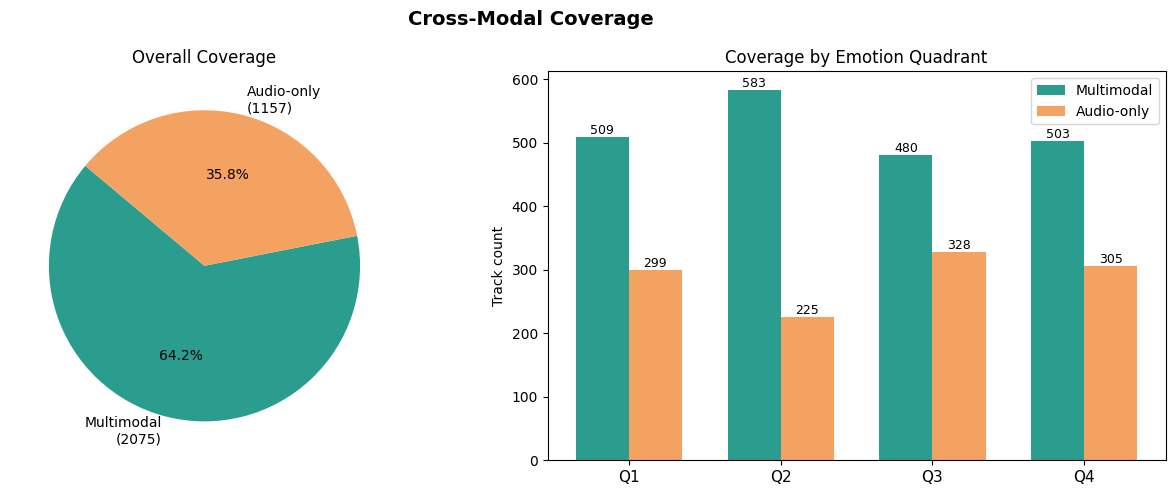

Saved: coverage.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Cross-Modal Coverage', fontsize=14, fontweight='bold')

# Left: overall coverage pie
multimodal  = df['is_multimodal'].sum()
audio_only  = (df['has_audio'] & ~df['has_lyrics']).sum()
no_audio    = (~df['has_audio']).sum()
labels = [f'Multimodal\n({multimodal})', f'Audio-only\n({audio_only})', f'No audio\n({no_audio})']
sizes  = [multimodal, audio_only, no_audio]
colors = ['#2a9d8f', '#f4a261', '#adb5bd']
axes[0].pie([s for s in sizes if s > 0],
            labels=[l for l, s in zip(labels, sizes) if s > 0],
            colors=[c for c, s in zip(colors, sizes) if s > 0],
            autopct='%1.1f%%', startangle=140, textprops={'fontsize': 10})
axes[0].set_title('Overall Coverage')

# Right: multimodal coverage per quadrant
cov = df.groupby('quadrant').agg(
    multimodal=('is_multimodal', 'sum'),
    audio_only=('has_audio', lambda x: (x & ~df.loc[x.index, 'has_lyrics']).sum()),
    total=('song_id', 'count')
).reset_index()
cov['quadrant_label'] = cov['quadrant'].map(QUADRANT_LABELS)
x = np.arange(len(cov))
w = 0.35
axes[1].bar(x - w/2, cov['multimodal'], w, label='Multimodal', color='#2a9d8f')
axes[1].bar(x + w/2, cov['audio_only'], w, label='Audio-only', color='#f4a261')
axes[1].set_xticks(x)
axes[1].set_xticklabels(cov['quadrant'], fontsize=11)
axes[1].set_ylabel('Track count')
axes[1].set_title('Coverage by Emotion Quadrant')
axes[1].legend()
for i, row in cov.iterrows():
    axes[1].text(i - w/2, row['multimodal'] + 5, str(int(row['multimodal'])), ha='center', fontsize=9)
    axes[1].text(i + w/2, row['audio_only'] + 5, str(int(row['audio_only'])), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coverage.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: coverage.png')

### 7b. Arousal–Valence Space (Russell's Circumplex)

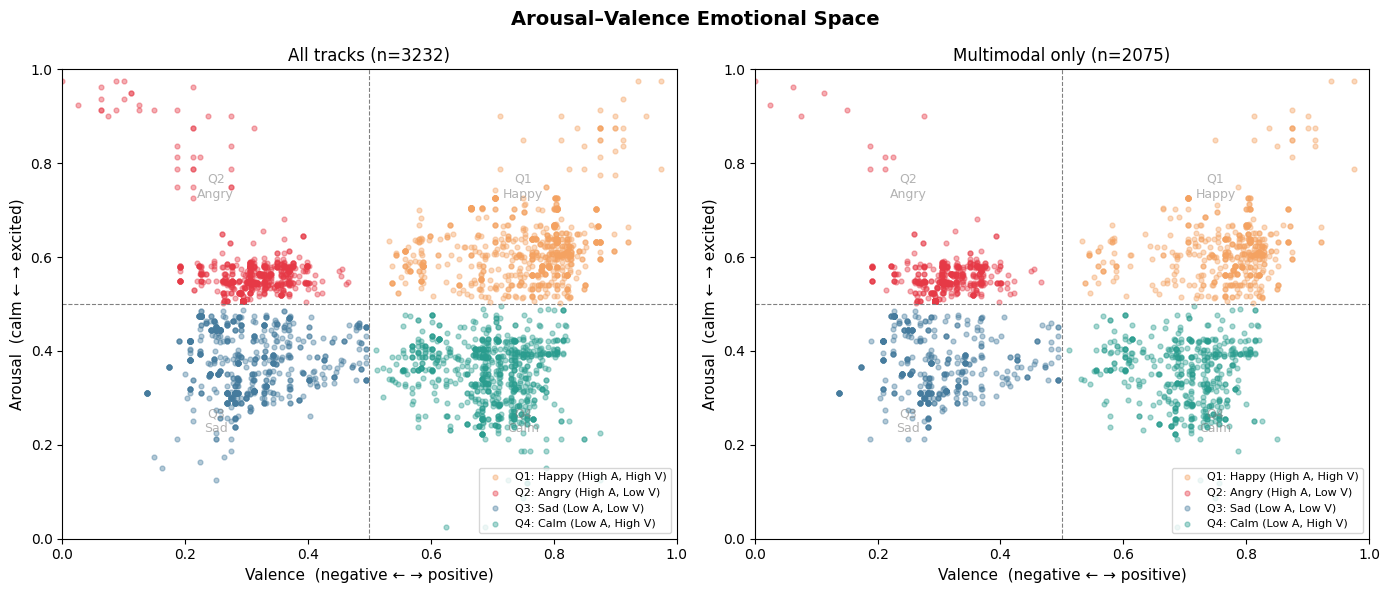

Saved: av_scatter.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Arousal–Valence Emotional Space', fontsize=14, fontweight='bold')

for ax, subset_label, mask in [
    (axes[0], 'All tracks', df['has_audio']),
    (axes[1], 'Multimodal only', df['is_multimodal']),
]:
    subset = df[mask]
    for q, color in QUADRANT_COLORS.items():
        qdf = subset[subset['quadrant'] == q]
        ax.scatter(qdf['valence'], qdf['arousal'],
                   c=color, alpha=0.4, s=12, label=f'{q}: {QUADRANT_LABELS[q]}')
    ax.axvline(0.5, color='gray', linewidth=0.8, linestyle='--')
    ax.axhline(0.5, color='gray', linewidth=0.8, linestyle='--')
    ax.set_xlabel('Valence  (negative ← → positive)', fontsize=11)
    ax.set_ylabel('Arousal  (calm ← → excited)', fontsize=11)
    ax.set_title(f'{subset_label} (n={len(subset)})')
    ax.legend(fontsize=8, loc='lower right')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    # Quadrant labels
    for txt, xy in [('Q1\nHappy', (0.75, 0.75)), ('Q2\nAngry', (0.25, 0.75)),
                    ('Q3\nSad',   (0.25, 0.25)), ('Q4\nCalm', (0.75, 0.25))]:
        ax.text(xy[0], xy[1], txt, ha='center', va='center',
                fontsize=9, color='gray', alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'av_scatter.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: av_scatter.png')

### 7c. Arousal & Valence Distributions per Quadrant

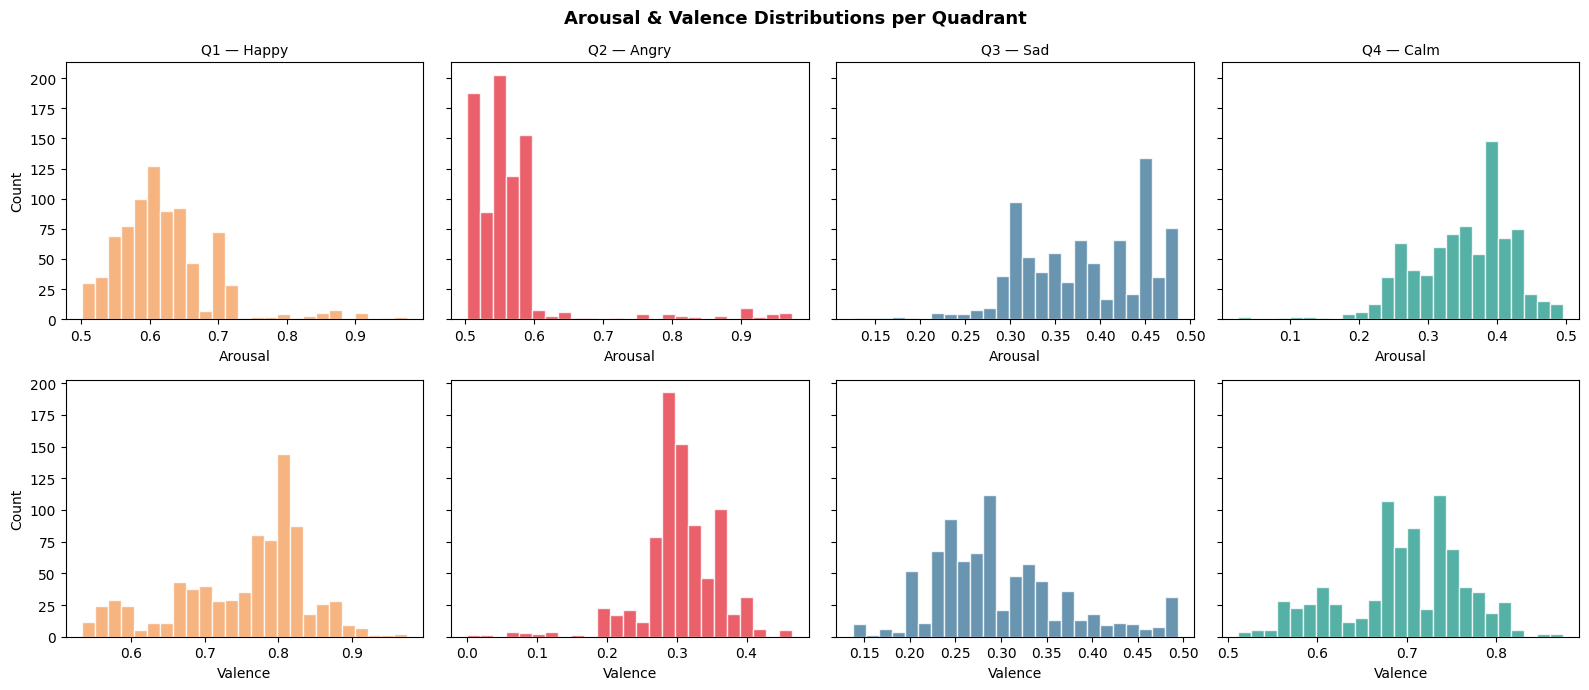

Saved: av_distributions.png


In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey='row')
fig.suptitle('Arousal & Valence Distributions per Quadrant', fontsize=13, fontweight='bold')

for col, (q, color) in enumerate(QUADRANT_COLORS.items()):
    qdf = df[df['quadrant'] == q]
    axes[0, col].hist(qdf['arousal'].dropna(), bins=25, color=color, alpha=0.8, edgecolor='white')
    axes[0, col].set_title(f'{q} — {QUADRANT_LABELS[q].split(" ")[0]}', fontsize=10)
    axes[0, col].set_xlabel('Arousal')
    if col == 0:
        axes[0, col].set_ylabel('Count')

    axes[1, col].hist(qdf['valence'].dropna(), bins=25, color=color, alpha=0.8, edgecolor='white')
    axes[1, col].set_xlabel('Valence')
    if col == 0:
        axes[1, col].set_ylabel('Count')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'av_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: av_distributions.png')

### 7d. Audio Duration & Lyrics Word Count

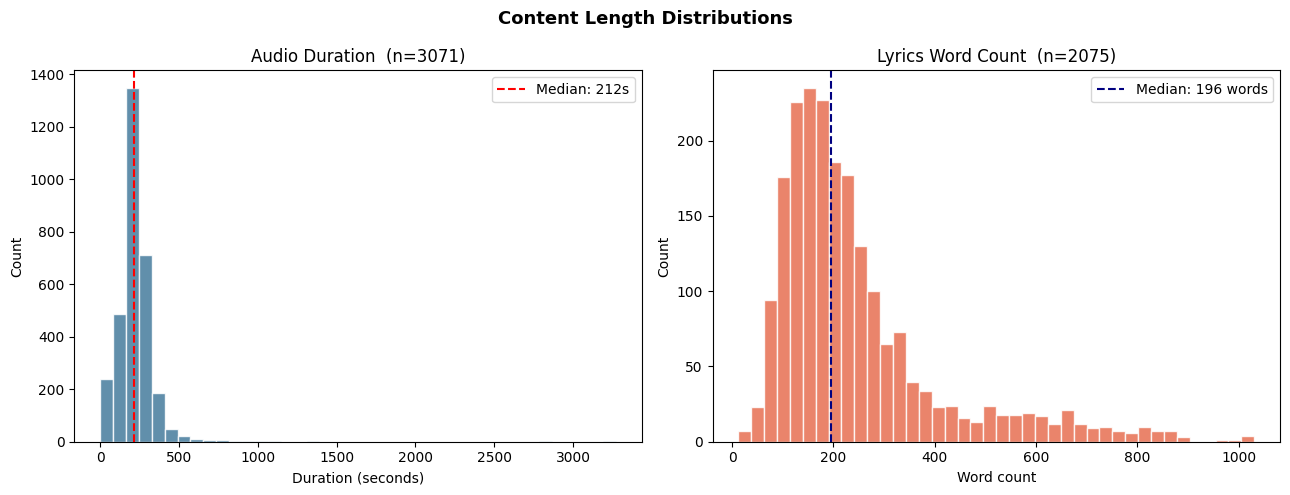

Saved: content_lengths.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Content Length Distributions', fontsize=13, fontweight='bold')

# Duration
dur = df[df['duration_sec'].notna()]['duration_sec']
axes[0].hist(dur, bins=40, color='#457b9d', alpha=0.85, edgecolor='white')
axes[0].axvline(dur.median(), color='red', linestyle='--', linewidth=1.5,
                label=f'Median: {dur.median():.0f}s')
axes[0].set_xlabel('Duration (seconds)')
axes[0].set_ylabel('Count')
axes[0].set_title(f'Audio Duration  (n={len(dur)})')
axes[0].legend()

# Lyrics word count
wc = df[df['lyrics_word_count'] > 0]['lyrics_word_count']
axes[1].hist(wc, bins=40, color='#e76f51', alpha=0.85, edgecolor='white')
axes[1].axvline(wc.median(), color='navy', linestyle='--', linewidth=1.5,
                label=f'Median: {wc.median():.0f} words')
axes[1].set_xlabel('Word count')
axes[1].set_ylabel('Count')
axes[1].set_title(f'Lyrics Word Count  (n={len(wc)})')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'content_lengths.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: content_lengths.png')

### 7e. Year Distribution

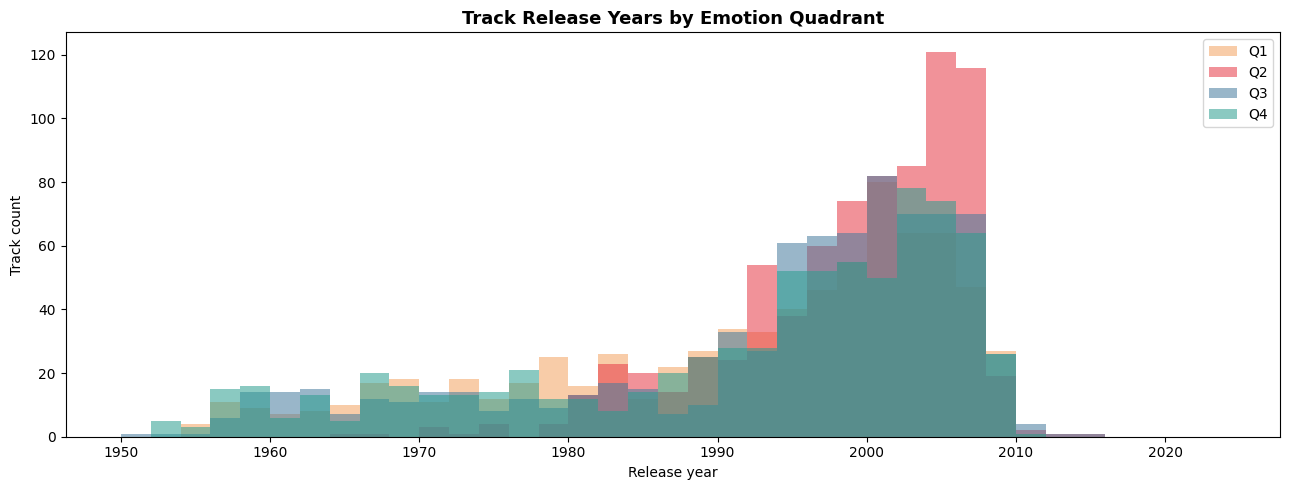

Saved: year_distribution.png


In [13]:
year_data = df[df['year'].notna()].copy()
year_data['year'] = pd.to_numeric(year_data['year'], errors='coerce')
year_data = year_data[year_data['year'].between(1900, 2030)]

fig, ax = plt.subplots(figsize=(13, 5))
for q, color in QUADRANT_COLORS.items():
    qdf = year_data[year_data['quadrant'] == q]
    ax.hist(qdf['year'], bins=range(1950, 2026, 2), alpha=0.55,
            color=color, label=q, edgecolor='none')
ax.set_xlabel('Release year')
ax.set_ylabel('Track count')
ax.set_title('Track Release Years by Emotion Quadrant', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'year_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: year_distribution.png')

### 7f. Top Genres and Moods (Evaluation Metadata — Not Used as Features)

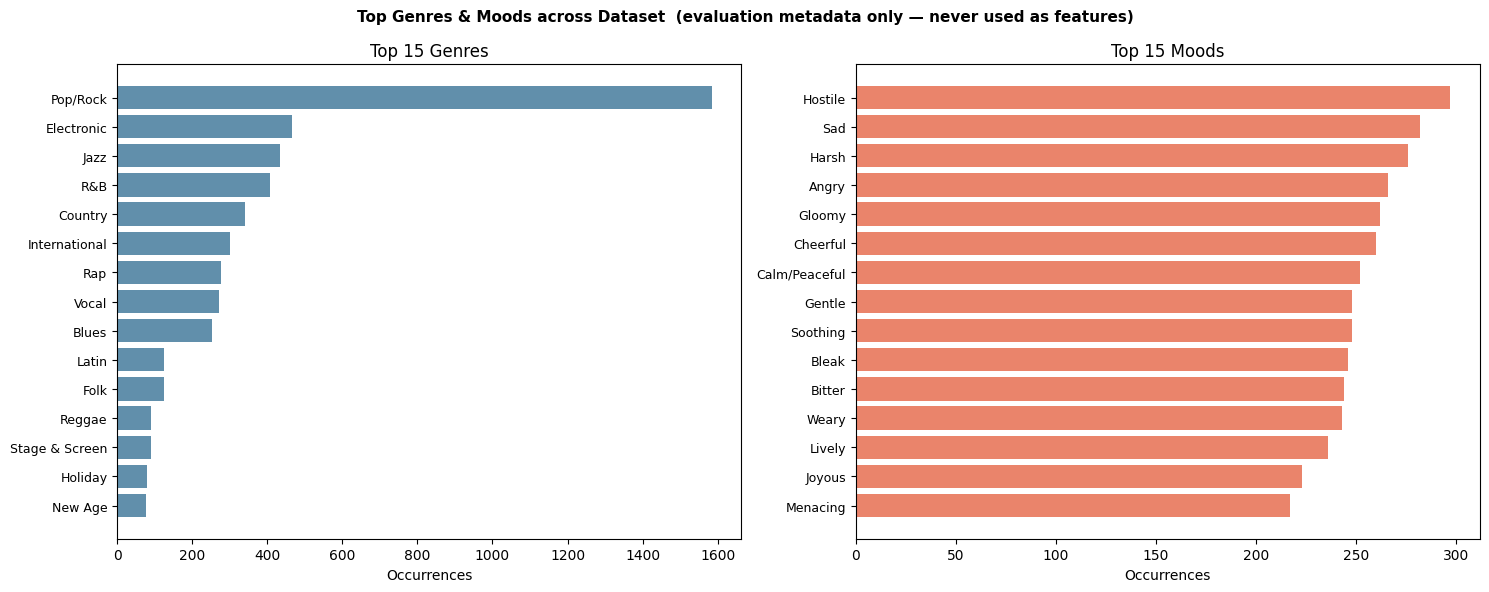

Saved: genres_moods.png


In [14]:
from collections import Counter

def top_tags(series, n=15):
    counts = Counter()
    for val in series.dropna():
        for tag in str(val).split(','):
            tag = tag.strip()
            if tag:
                counts[tag] += 1
    return pd.DataFrame(counts.most_common(n), columns=['tag', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Top Genres & Moods across Dataset  (evaluation metadata only — never used as features)',
             fontsize=11, fontweight='bold')

for ax, col, title, color in [
    (axes[0], 'genres', 'Top 15 Genres', '#457b9d'),
    (axes[1], 'moods',  'Top 15 Moods',  '#e76f51'),
]:
    top = top_tags(df[col])
    ax.barh(top['tag'][::-1], top['count'][::-1], color=color, alpha=0.85)
    ax.set_xlabel('Occurrences')
    ax.set_title(title, fontsize=12)
    ax.tick_params(axis='y', labelsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'genres_moods.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: genres_moods.png')

### 7g. AV Stats per Quadrant

In [15]:
stats = df.groupby('quadrant')[['arousal', 'valence']].agg(['mean', 'std', 'min', 'max']).round(3)
stats.columns = ['_'.join(c) for c in stats.columns]

# Cross-modal coverage per quadrant
coverage = df.groupby('quadrant').agg(
    total=('song_id', 'count'),
    multimodal=('is_multimodal', 'sum'),
    audio_only=('has_audio', lambda x: (x & ~df.loc[x.index, 'has_lyrics']).sum()),
)
coverage['pct_multimodal'] = (coverage['multimodal'] / coverage['total'] * 100).round(1)

summary = stats.join(coverage)
summary.index = [f"{q} ({QUADRANT_LABELS[q]})" for q in summary.index]
print('=== Dataset Summary per Quadrant ===')
print(summary.to_string())

=== Dataset Summary per Quadrant ===
                             arousal_mean  arousal_std  arousal_min  arousal_max  valence_mean  valence_std  valence_min  valence_max  total  multimodal  audio_only  pct_multimodal
Q1 (Happy (High A, High V))         0.621        0.073        0.501        0.975         0.753        0.089        0.532        0.975    808         509         299            63.0
Q2 (Angry (High A, Low V))          0.562        0.076        0.503        0.975         0.306        0.056        0.000        0.466    808         583         225            72.2
Q3 (Sad (Low A, Low V))             0.382        0.067        0.125        0.486         0.297        0.074        0.138        0.494    808         480         328            59.4
Q4 (Calm (Low A, High V))           0.351        0.069        0.025        0.496         0.697        0.068        0.511        0.875    808         503         305            62.3


## 8. Sample Inspection

In [16]:
# Spot-check a multimodal track from each quadrant
pd.set_option('display.max_colwidth', 80)
for q in ['Q1', 'Q2', 'Q3', 'Q4']:
    sample = df[(df['quadrant'] == q) & df['is_multimodal']].sample(1, random_state=42)
    row = sample.iloc[0]
    print(f"\n{'='*60}")
    print(f"[{q}] {row['artist']} — {row['title']}")
    print(f"  Arousal: {row['arousal']:.3f}  Valence: {row['valence']:.3f}")
    print(f"  Audio: {os.path.basename(row['audio_path'])}")
    preview = (row['lyrics_text'] or '')[:200].replace('\n', ' ')
    print(f"  Lyrics preview: {preview}...")

## Phase 1 Complete

**Output:** `outputs/merged_dataset.parquet`

**What's in it:**
- 3,232 rows (all tracks from `merge_audio_balanced_metadata.csv`)
- `is_multimodal = True` for tracks that have both an audio file and a lyrics file
- `moods`, `genres`, `themes` retained for **evaluation only** — never touch these in feature extraction

**Next:** Phase 2 — Acoustic Feature Extraction (`phase2_audio_features.ipynb`)